**To design and develop a production-ready Credit Risk Machine Learning System that predicts the probability of loan default while providing reliable, interpretable, and well-calibrated predictions.**

**REQUIRED LIBRARY**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings
warnings.filterwarnings('ignore')

**1. Load Dataset**

In [ ]:
df=pd.read_csv('credit_risk_dataset.csv')
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


**2. EDA**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [ ]:
df.shape

(32581, 12)

In [ ]:
df.isnull().sum()


,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [ ]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


**Target Dataset**

In [ ]:
print(f"Unique Data_point.... {df['loan_status'].unique()}")
df['loan_status'].value_counts()

Unique Data_point.... [1 0]


,count
loan_status,
0,25473
1,7108


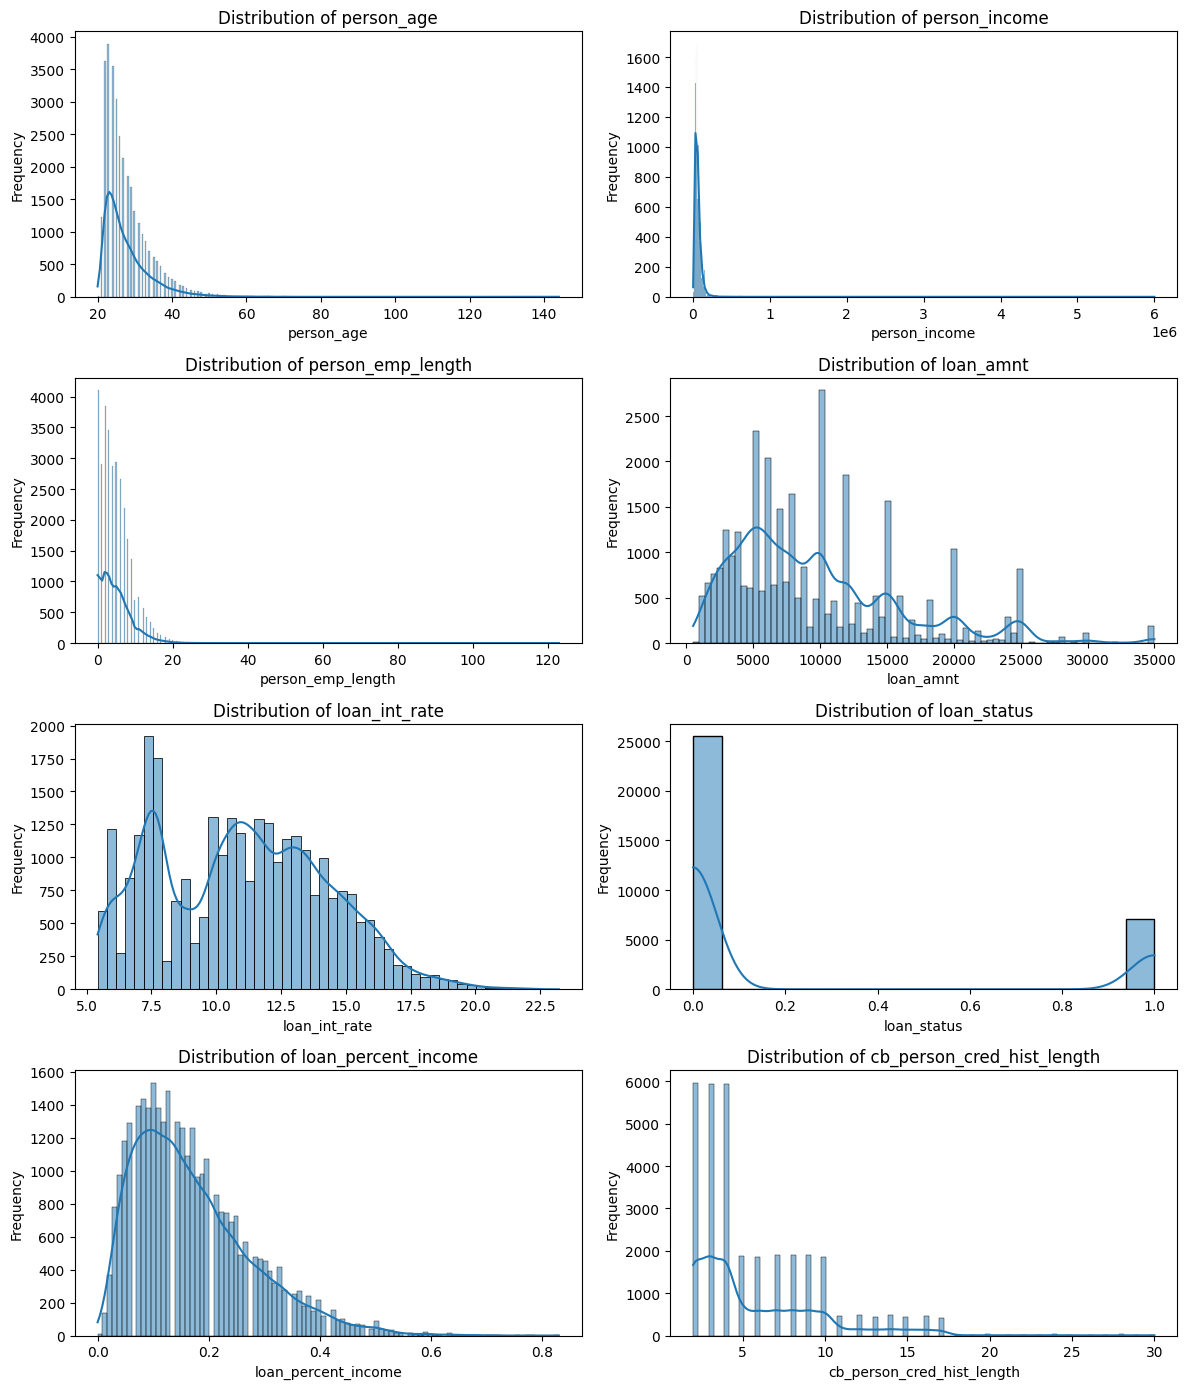

In [ ]:
num_cols = df.select_dtypes(include=np.number).columns[:8]

# Create 4 × 2 grid
fig, axes = plt.subplots(4, 2, figsize=(12, 14))

# Plot each numerical feature
for ax, col in zip(axes.flatten(), num_cols):
    sns.histplot(data=df, x=col, kde=True, ax=ax)
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')

# Adjust spacing
plt.tight_layout()
plt.show()

In [ ]:
# Previous default history (cb person default on file)

In [ ]:
pd.crosstab(
    df['cb_person_default_on_file'],
    df['loan_status'],
    normalize='index'
) * 100

loan_status,0,1
cb_person_default_on_file,,
N,81.606797,18.393203
Y,62.193211,37.806789


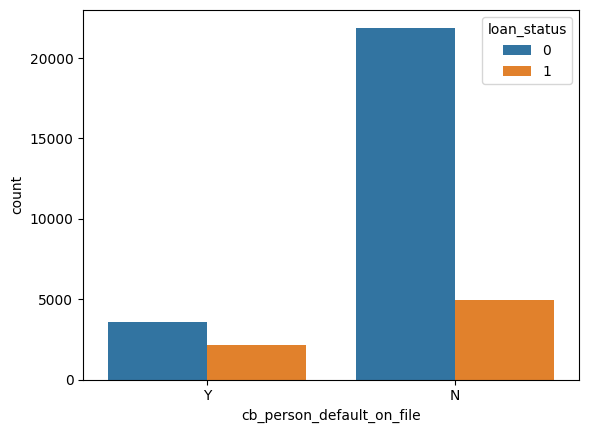

In [ ]:
sns.countplot(
    data=df,
    x='cb_person_default_on_file',
    hue='loan_status'
)
plt.show()

In [ ]:
##loan_grade

In [ ]:
df.groupby('loan_grade')['loan_status'].mean() * 100

,loan_status
loan_grade,
A,9.956389
B,16.275954
C,20.733973
D,59.045780
E,64.419087
F,70.539419
G,98.437500


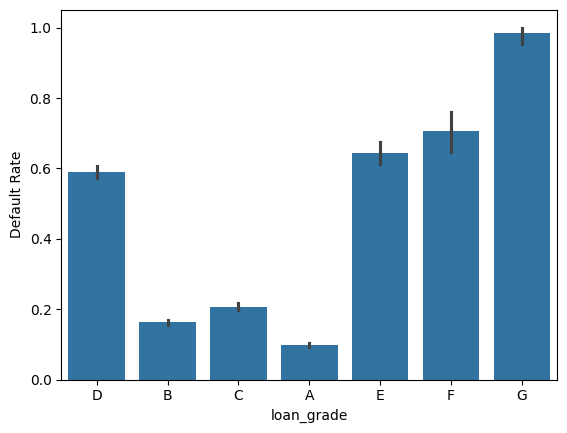

In [ ]:
sns.barplot(
    data=df,
    x='loan_grade',
    y='loan_status'
)
plt.ylabel('Default Rate')
plt.show()

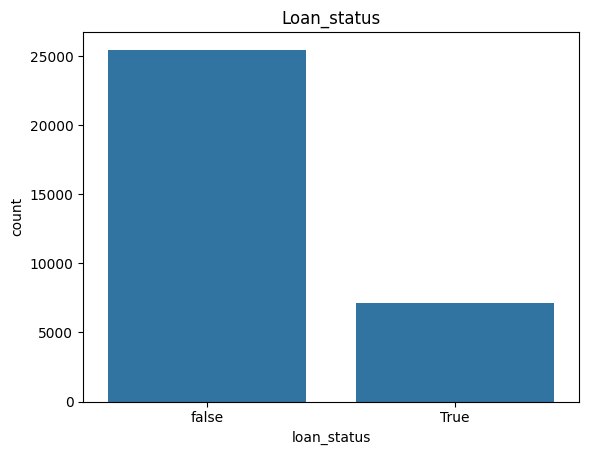

In [ ]:
ax = sns.countplot(x='loan_status',data=df)
plt.title('Loan_status')
ax.set_xticklabels(['false', 'True'])
plt.show()

**Outlier**

In [ ]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


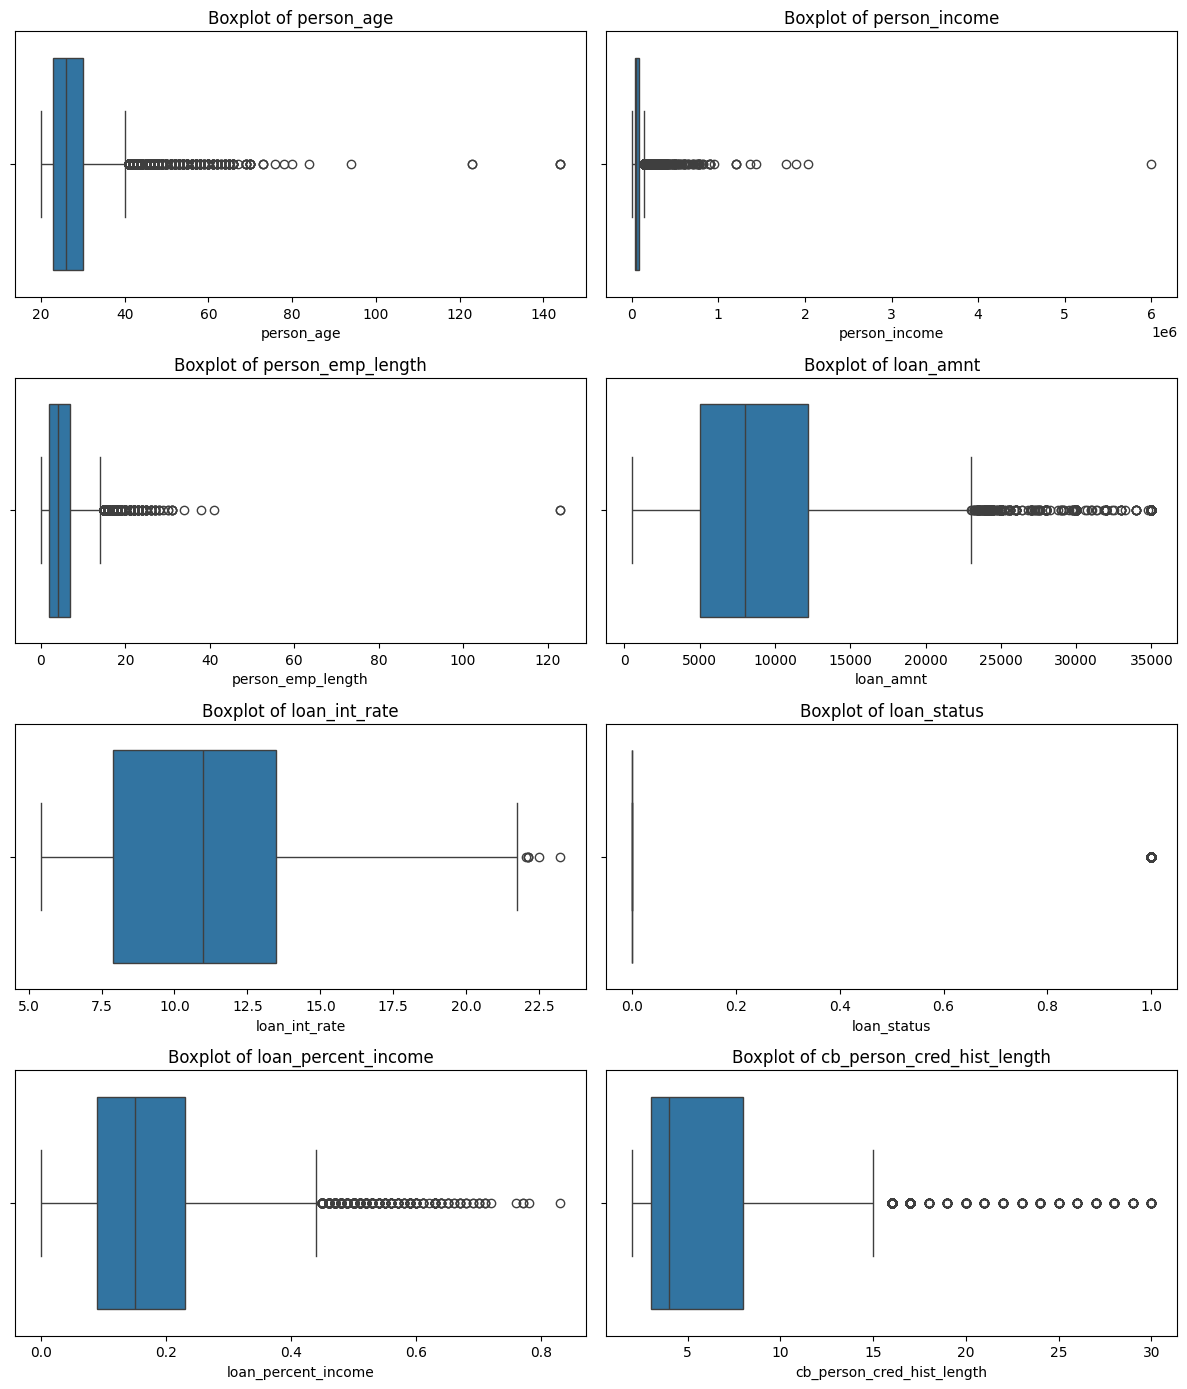

In [ ]:
# Select numerical columns
numerical_col = df.select_dtypes(include=np.number).columns[:8]

# Create 4 rows × 2 columns
fig, axes = plt.subplots(4, 2, figsize=(12, 14))

for ax, col in zip(axes.flatten(), numerical_col):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

In [ ]:
print(f"Number of Age outlier {(df['person_age']>100).sum()}")

print(f"Number of emp_length outlier {(df['person_emp_length']>40).sum()}")

Number of Age outlier 5
Number of emp_length outlier 3


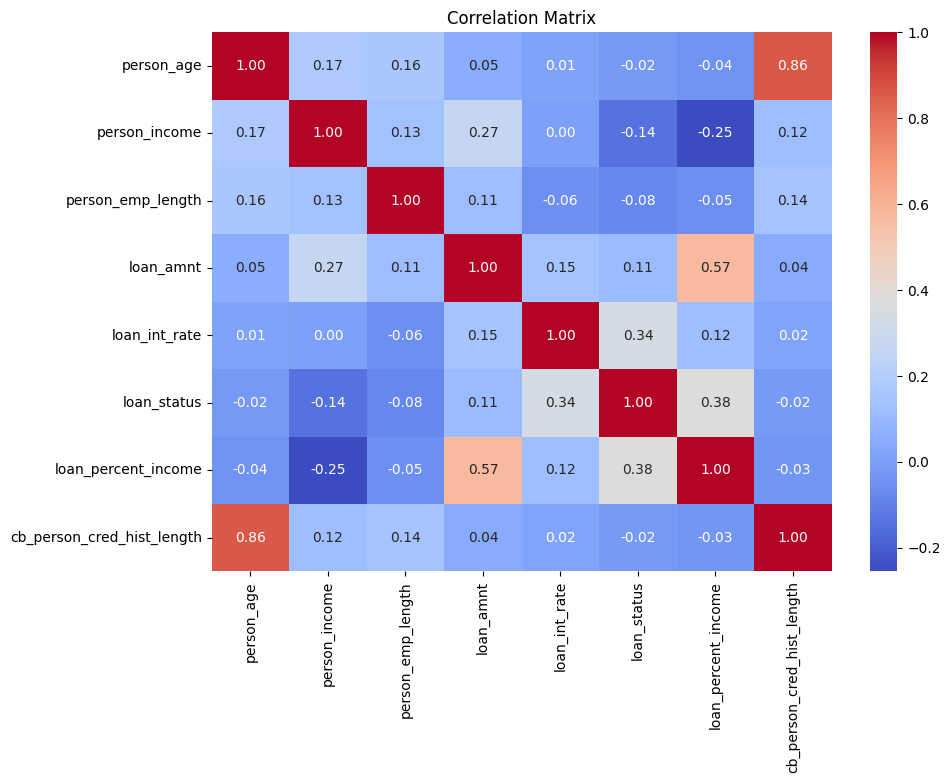

In [ ]:
corr = df[list(num_cols) ].corr()

plt.figure(figsize=(10,7))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Matrix')
plt.show()

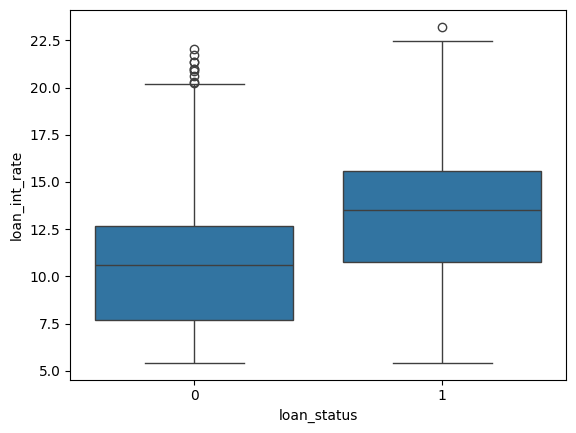

In [ ]:
sns.boxplot(
    data=df,
    x='loan_status',
    y='loan_int_rate'
)
plt.show()

In [ ]:
def default_rate_by_feature(df, feature):
    result = (
        df.groupby(feature)['loan_status']
        .agg(['count', 'mean'])
        .rename(columns={'mean': 'default_rate'})
    )

    result['default_rate'] *= 100
    return result.sort_values('default_rate', ascending=False)

In [ ]:
default_rate_by_feature(df, 'loan_grade')

,count,default_rate
loan_grade,,
G,64,98.437500
F,241,70.539419
E,964,64.419087
D,3626,59.045780
C,6458,20.733973
B,10451,16.275954
A,10777,9.956389


In [ ]:
default_rate_by_feature(df, 'person_home_ownership')

,count,default_rate
person_home_ownership,,
RENT,16446,31.569987
OTHER,107,30.841121
MORTGAGE,13444,12.570663
OWN,2584,7.469040


In [ ]:
default_rate_by_feature(df, 'cb_person_default_on_file')

,count,default_rate
cb_person_default_on_file,,
Y,5745,37.806789
N,26836,18.393203


In [ ]:
## Credit Score → Default

In [ ]:
pd.crosstab(
    df['loan_grade'],
    df['cb_person_default_on_file'],
    values=df['loan_status'],
    aggfunc='mean'
) * 100

cb_person_default_on_file,N,Y
loan_grade,,
A,9.956389,NaN
B,16.275954,NaN
C,21.798876,19.686732
D,57.942857,60.074627
E,66.132265,62.580645
F,71.317829,69.642857
G,100.000000,97.222222


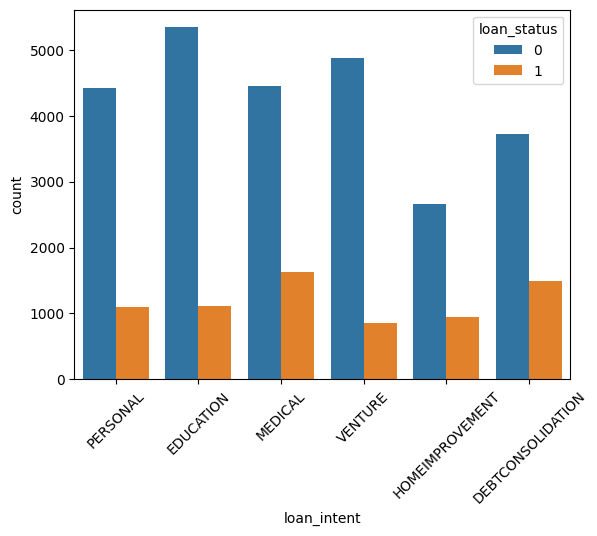

In [ ]:
sns.countplot(
    data=df,
    x='loan_intent',
    hue='loan_status'
)

plt.xticks(rotation=45)
plt.show()

**3. DATA VALIDATION & OUTLIER HANDLING**

In [ ]:
df.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='object')

In [ ]:
df_copy = df.copy()

print(f"Original rows: {df_copy.shape[0]}")

# Remove duplicate rows
df_copy = df_copy.drop_duplicates()

# Keep only valid values
df_copy = df_copy[
    (df_copy['person_age'].between(18, 100)) &
    (df_copy['person_emp_length']).between(0, 60) &
    (df_copy['loan_amnt'] >= 0) &
    (df_copy['loan_percent_income'] >= 0)
]

print(f"After rows: {df_copy.shape[0]}")

Original rows: 32581
After rows: 31522


In [ ]:
df_copy.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,31522.000000,3.152200e+04,31522.000000,31522.000000,28495.000000,31522.000000,31522.000000,31522.000000
mean,27.742529,6.650168e+04,4.782850,9663.771334,11.045220,0.215944,0.169658,5.816097
std,6.218713,5.275216e+04,4.037343,6334.787700,3.230786,0.411482,0.106296,4.063622
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.943800e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.600000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,8.000000e+04,7.000000,12500.000000,13.480000,0.000000,0.230000,8.000000
max,94.000000,2.039784e+06,41.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [ ]:
df_copy.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,0
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3027
loan_status,0
loan_percent_income,0


In [ ]:
(df_copy.isnull().sum() / len(df_copy)) * 100

,0
person_age,0.000000
person_income,0.000000
person_home_ownership,0.000000
person_emp_length,0.000000
loan_intent,0.000000
loan_grade,0.000000
loan_amnt,0.000000
loan_int_rate,9.602817
loan_status,0.000000
loan_percent_income,0.000000


In [ ]:
df_copy['loan_int_rate'] = (
    df_copy.groupby('loan_grade')['loan_int_rate']
    .transform(lambda x: x.fillna(x.median()))
)

**df_copy is now ready for preprocessing...**

**Feature Target & train-Test Split**

In [ ]:
X=df_copy.drop('loan_status',axis=1)
y=df_copy['loan_status']

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [ ]:
numeric_col = X_train.select_dtypes(include=np.number).columns
categoric_col = X_train.select_dtypes(exclude=np.number).columns

**Handle Class Imblamce**

In [ ]:
y_train.value_counts()

,count
loan_status,
0,19772
1,5445


In [ ]:
#class  weight...
from sklearn.utils import class_weight
class_weights = class_weight.compute_class_weight('balanced',classes=np.unique(y_train),y=y_train)

print(class_weights)

[0.63769472 2.31561065]


**Data Preprocessing - Pipeline & column Transformer**

**Preprocessing for Logistic Regression**

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

**Logistic Regression**

In [ ]:
# logistic : impute + Scale_numeric , impute + one_hot_encoding

In [ ]:
preprocessor_lr=ColumnTransformer(
    transformers=[
        #pipeline for numerical column
        ('num',Pipeline([
            ('imputer',SimpleImputer(strategy='median')),
            ('scaler',StandardScaler())
        ]),numeric_col),
        #pipeline for categorical column
        ('cat',Pipeline([
            ('imputer',SimpleImputer(strategy='constant',fill_value='Missing')),
            ('onehot',OneHotEncoder(handle_unknown='ignore'))
        ]),categoric_col)
    ]
)

preprocessor_lr


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'],
      dtype='object')),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(fill_value='Missing',
                                                                strategy='constant')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 Index(['person_home_ownership', 'loan_intent', 'loan_grade',
       'cb_person_default_on_file'],
      dtype='object'))])

**XG_boost Pipeline**

In [ ]:
#XGboost: impute numeric only (no scaling), impute + one-hot encoding

Xg_preprocessor=ColumnTransformer(
    transformers=[
        #pipeline for numerical column
        ('num',Pipeline([
            ('imputer',SimpleImputer(strategy='median'))
        ]),numeric_col),
        #pipeline for categorical column
        ('cat',Pipeline([
            ('imputer',SimpleImputer(strategy='constant',fill_value='Missing')),
            ('onehot',OneHotEncoder(handle_unknown='ignore'))
    ])
        )
    ])

Xg_preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median'))]),
                                 Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'],
      dtype='object')),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(fill_value='Missing',
                                                                strategy='constant')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]))])

**Stratified Cross_validation**

In [ ]:
#Logistic_model
from sklearn.model_selection import StratifiedKFold
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
scoring = {
    'roc_auc': 'roc_auc',
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1':'f1'
    }

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score
lr_cv_pipeline=Pipeline([
    ('preprocessor',preprocessor_lr),
    ('classifier',LogisticRegression(class_weight='balanced',max_iter=1000,random_state=42))
])
lr_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['person_home_ownership', 'loan_intent', 'loan_grade',
       'cb_person_default_on_file'],
      dtype='object'))])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [ ]:
#XGBoost Model
from xgboost import XGBClassifier
Xg_cv_pipeline=Pipeline([
    ('preprocessor',Xg_preprocessor),
    ('classifier',XGBClassifier(
        random_state=42, learning_rate=0.01,n_jobs=-1,max_depth=5,
        n_estimators=1000,scale_pos_weight=class_weights[1]
    ))
])
Xg_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Mis...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.01,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=1000, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [ ]:
#Evaluation model
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_curve,
    roc_auc_score
)

import seaborn as sns
import matplotlib.pyplot as plt


def evaluate_model(model, X_test, y_test):

    # Predictions
    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)[:, 1]

    # -----------------------------
    # Evaluation Metrics
    # -----------------------------

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_pred_proba)

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1 Score : {f1:.4f}")
    print(f"ROC-AUC  : {roc_auc:.4f}")

    # -----------------------------
    # Classification Report
    # -----------------------------

    print("\nWhat did the model get wrong?")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    # -----------------------------
    # Confusion Matrix
    # -----------------------------

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Predicted 0', 'Predicted 1'],
        yticklabels=['Actual 0', 'Actual 1']
    )

    plt.xlabel('Predicted Values')
    plt.ylabel('Actual Values')
    plt.title('Confusion Matrix')
    plt.show()

    print("\nTN → Good customer correctly identified as good\n TP → Risky customer correctly identified as risky\n FP → Good customer incorrectly flagged as risky\n FN → Risky customer incorrectly classified as good\n")

    # -----------------------------
    # Precision-Recall Curve
    # -----------------------------

    precisions, recalls, pr_thresholds = precision_recall_curve(
        y_test,
        y_pred_proba
    )

    plt.figure(figsize=(7, 5))

    plt.plot(
        recalls,
        precisions,
        label='Precision-Recall Curve'
    )

    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title(
        f'{model.__class__.__name__} - Precision-Recall Curve'
    )

    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    print("\nPrecision = How many predicted risky customers were actually risky?\n Recall = How many actual risky customers did we successfully detect?\n")
    # -----------------------------
    # ROC Curve
    # -----------------------------

    fpr, tpr, roc_thresholds = roc_curve(
        y_test,
        y_pred_proba
    )

    plt.figure(figsize=(7, 5))

    plt.plot(
        fpr,
        tpr,
        label=f'ROC Curve (AUC = {roc_auc:.4f})'
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle='--',
        label='Random Classifier'
    )

    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(
        f'{model.__class__.__name__} - ROC Curve'
    )

    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    print(f"\nThe model has good discriminatory ability, with an AUC of {roc_auc:4f}, meaning it generally ranks risky customers above non-risky customers.\n")

**Cross_validation**

In [ ]:
from sklearn.model_selection import cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from xgboost import XGBClassifier

# Redefine the fixed Xg_preprocessor in-place
Xg_preprocessor = ColumnTransformer(
    transformers=[
        # pipeline for numerical column
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median'))
        ]), numeric_col),
        # pipeline for categorical column (fixed by appending categoric_col)
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categoric_col)
    ]
)

# Recreate the XGBoost pipeline with the corrected preprocessor
Xg_cv_pipeline = Pipeline([
    ('preprocessor', Xg_preprocessor),
    ('classifier', XGBClassifier(
        random_state=42, learning_rate=0.01, n_jobs=-1, max_depth=5,
        n_estimators=1000, scale_pos_weight=class_weights[1]
    ))
])

# Run the cross-validation loop
for cv_name, pipe in [
    ("Logistic Regression", lr_cv_pipeline),
    ("XGBoost", Xg_cv_pipeline)
]:
    cv_results = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=True
    )

    print(f"\n{cv_name}")
    print(f"ROC_AUC: {cv_results['test_roc_auc'].mean():.4f} ")
    print(f"Accuracy: {cv_results['test_accuracy'].mean():.4f}")
    print(f"Precision: {cv_results['test_precision'].mean():.4f}")
    print(f"Recall: {cv_results['test_recall'].mean():.4f}")
    print(f"F1_score: {cv_results['test_f1'].mean():.4f}")


Logistic Regression
ROC_AUC: 0.8707 
Accuracy: 0.8116
Precision: 0.5449
Recall: 0.7783
F1_score: 0.6409

XGBoost
ROC_AUC: 0.9391 
Accuracy: 0.9277
Precision: 0.8950
Recall: 0.7541
F1_score: 0.8183


**BaseLine Model**

In [ ]:
baseline_model=Pipeline([
    ('preprocessor',preprocessor_lr),
    ('classifier',LogisticRegression(class_weight='balanced',max_iter=1000,random_state=42))
])

baseline_model.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['person_home_ownership', 'loan_intent', 'loan_grade',
       'cb_person_default_on_file'],
      dtype='object'))])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

Accuracy : 0.8181
Precision: 0.5558
Recall   : 0.7863
F1 Score : 0.6513
ROC-AUC  : 0.8754

What did the model get wrong?

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.74      0.81      0.76      6305
weighted avg       0.85      0.82      0.83      6305



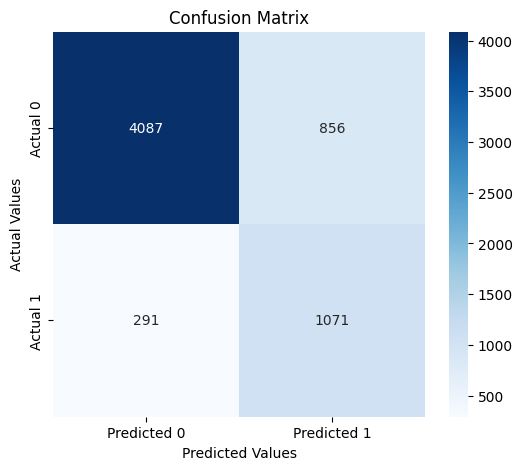


TN → Good customer correctly identified as good
 TP → Risky customer correctly identified as risky
 FP → Good customer incorrectly flagged as risky
 FN → Risky customer incorrectly classified as good



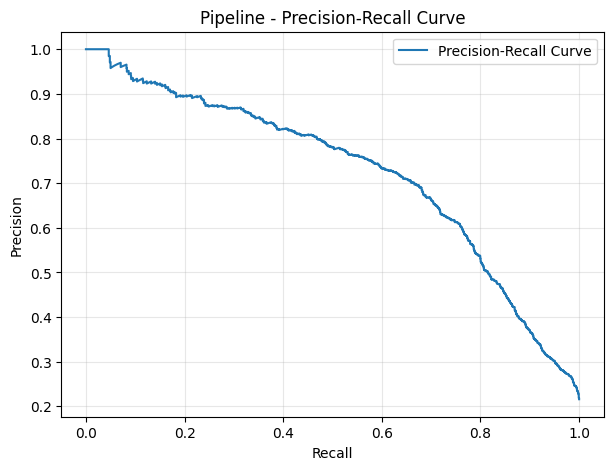


Precision = How many predicted risky customers were actually risky?
 Recall = How many actual risky customers did we successfully detect?



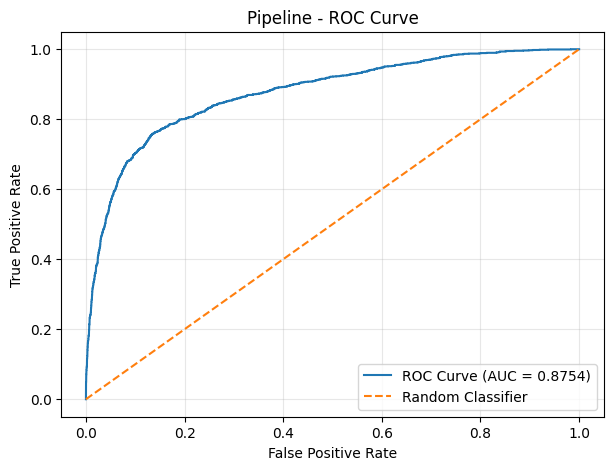


The model has good discriminatory ability, with an AUC of 0.875437, meaning it generally ranks risky customers above non-risky customers.



In [ ]:
#Evaluation of LOgistic_model

evaluate_model(baseline_model,X_test,y_test)

In [ ]:
#XGBoost Model

Xg_model=Pipeline([
    ('preprocessor',Xg_preprocessor),
    ('classifier',XGBClassifier( learning_rate=0.1,scale_pos_weight=class_weights[1]))
])
Xg_model.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Mis...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

Accuracy : 0.9315
Precision: 0.9093
Recall   : 0.7584
F1 Score : 0.8271
ROC-AUC  : 0.9489

What did the model get wrong?

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.98      0.96      4943
           1       0.91      0.76      0.83      1362

    accuracy                           0.93      6305
   macro avg       0.92      0.87      0.89      6305
weighted avg       0.93      0.93      0.93      6305



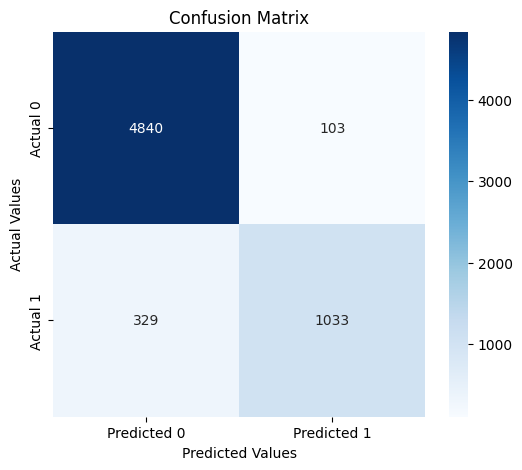


TN → Good customer correctly identified as good
 TP → Risky customer correctly identified as risky
 FP → Good customer incorrectly flagged as risky
 FN → Risky customer incorrectly classified as good



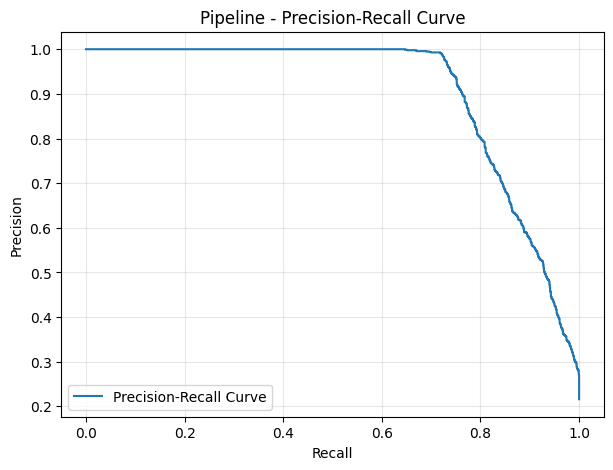


Precision = How many predicted risky customers were actually risky?
 Recall = How many actual risky customers did we successfully detect?



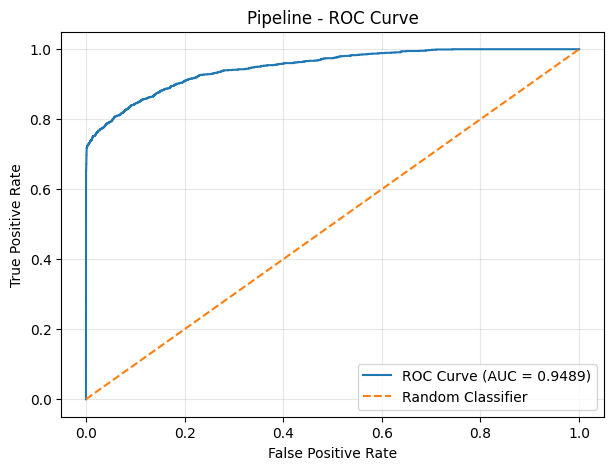


The model has good discriminatory ability, with an AUC of 0.948870, meaning it generally ranks risky customers above non-risky customers.



In [ ]:
#evaluation of Xg_model
evaluate_model(Xg_model,X_test,y_test)

**Hyperparameter tunning**

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# Fixed the parameter grid by adding the 'classifier__' prefix to all XGBoost parameters
param_grid = {
    # Number of boosting rounds
    'classifier__n_estimators': [100, 200, 300],

    # Learning rate
    'classifier__learning_rate': [0.01, 0.05, 0.2],

    # Maximum depth of each tree
    'classifier__max_depth': [3, 5, 8, 10],

    # Minimum loss reduction required for split
    'classifier__gamma': [ 0.1, 0.3, 0.5, 1],

    # Minimum sum of instance weight
    'classifier__min_child_weight': [1, 3, 5, 7],

    # Subsample ratio of training data
    'classifier__subsample': [0.5, 0.6, 0.7],

    # Subsample ratio of features
    'classifier__colsample_bytree': [0.4, 0.5, 0.6,0.7],

    # L1 regularization
    'classifier__reg_alpha': [0, 0.01, 0.1],

    # L2 regularization
    'classifier__reg_lambda': [0.1, 1, 5]
}

# =========================================================
# 3. Randomized Search
# =========================================================

random_search = RandomizedSearchCV(
    estimator=Xg_model,
    param_distributions=param_grid,
    n_iter=150,              # Number of random combinations
    scoring='roc_auc',      # Important for credit-risk problems
    cv=5,                   # 5-fold cross-validation
    verbose=2,
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)

# =========================================================
# 4. Fit RandomizedSearchCV
# =========================================================

random_search.fit(X_train, y_train)


Fitting 5 folds for each of 150 candidates, totalling 750 fits


RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'],
      dtype='object')),
                                                                              ('cat',
                                                                               Pipeline(steps=[('impu...
                                        'classifier__gamma': [0.1, 0.3, 0.5, 1],
                                        'classifier__learning_rate': [0.01,
                                                                      0.05,
                                                                      0.2],
                                        'classifier__max_depth': [3, 5, 8, 10],
                                        'classifier__min_child_weight': [1, 3,
                                                                         5, 7],
                                        'classifier__n_estimators': [100, 200,
                                                                     300],
                                        'classifier__reg_alpha': [0, 0.01, 0.1],
                                        'classifier__reg_lambda': [0.1, 1, 5],
                                        'classifier__subsample': [0.5, 0.6,
                                                                  0.7]},
                   random_state=42, return_train_score=True, scoring='roc_auc',
                   verbose=2)

In [ ]:
# =========================================================
# 5. Best Parameters
# =========================================================

print("\nBest Parameters:")
print(random_search.best_params_)

# =========================================================
# 6. Best Cross-Validation Score
# =========================================================

print("\nBest CV ROC-AUC:")
print(f"{random_search.best_score_:.4f}")

# =========================================================
# 7. Best Model
# =========================================================

best_xgb = random_search.best_estimator_
print("\nBest Model:")
print(best_xgb)


Best Parameters:
{'classifier__subsample': 0.7, 'classifier__reg_lambda': 0.1, 'classifier__reg_alpha': 0.01, 'classifier__n_estimators': 200, 'classifier__min_child_weight': 5, 'classifier__max_depth': 10, 'classifier__learning_rate': 0.05, 'classifier__gamma': 1, 'classifier__colsample_bytree': 0.7}

Best CV ROC-AUC:
0.9465

Best Model:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                           

Accuracy : 0.9356
Precision: 0.9223
Recall   : 0.7665
F1 Score : 0.8372
ROC-AUC  : 0.9495

What did the model get wrong?

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.98      0.96      4943
           1       0.92      0.77      0.84      1362

    accuracy                           0.94      6305
   macro avg       0.93      0.87      0.90      6305
weighted avg       0.94      0.94      0.93      6305



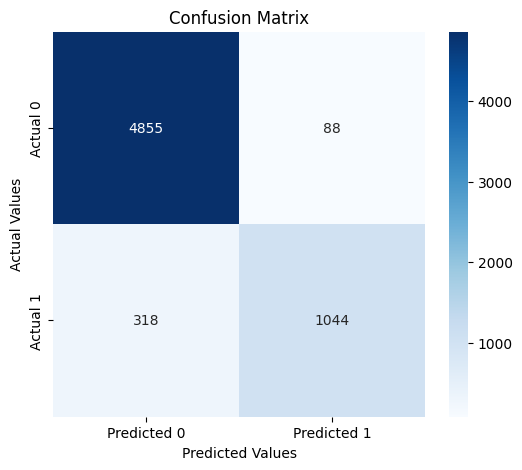


TN → Good customer correctly identified as good
 TP → Risky customer correctly identified as risky
 FP → Good customer incorrectly flagged as risky
 FN → Risky customer incorrectly classified as good



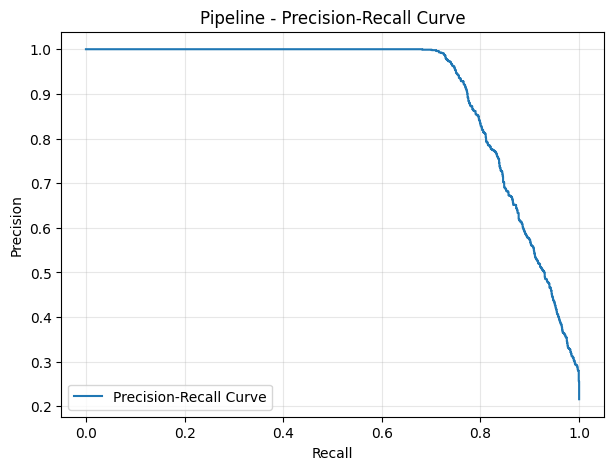


Precision = How many predicted risky customers were actually risky?
 Recall = How many actual risky customers did we successfully detect?



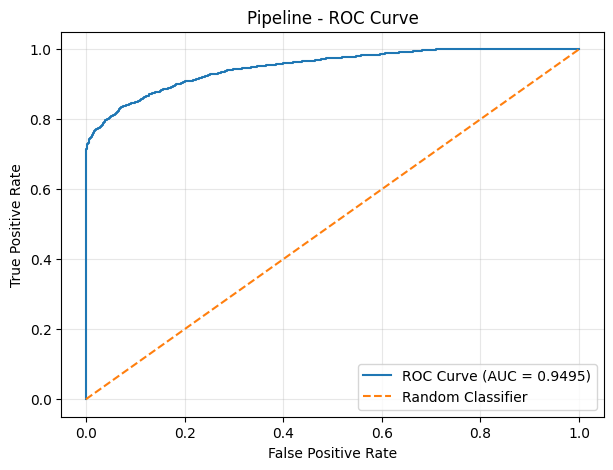


The model has good discriminatory ability, with an AUC of 0.949469, meaning it generally ranks risky customers above non-risky customers.



In [ ]:
evaluate_model(best_xgb,X_test,y_test)

**Optimizing the classification Threshold**

In [ ]:
# get the prob. of class 1 from XgBoost
prob = best_xgb.predict_proba(X_test)[:, 1]

# for each threshold calculate precision and Recall
precision, recall, thresholds = precision_recall_curve(y_test, prob)

# calculate the F1-score for each thershold
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-9)

# Get the threshold that produces the highest f1-score
best = np.argmax(f1_scores[:-1])
best_threshold = thresholds[best]  # Fixed: changed parenthesis () to square brackets []

print(f"Best Threshold: {best_threshold:.4f}")

# Evaluate the XGBoost model using that threshold.
y_pred_opt = (prob >= best_threshold).astype(int)

print("\nEvaluation with optimized threshold:")
print(f"Accuracy : {accuracy_score(y_test, y_pred_opt):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_opt):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_opt):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred_opt):.4f}")

Best Threshold: 0.5854

Evaluation with optimized threshold:
Accuracy : 0.9389
Precision: 0.9622
Recall   : 0.7467
F1 Score : 0.8408


**Probability Calibrartion**

    Probability calibration is the process of ensuring that a model's predicted probabilities accurately reflect the observed frequency of an event.

In [ ]:
'''

Methods by which we can fix the poorly calibrated model.
Platt scaling/sigmoid : adjust the probability using a sigmoid curve.
Iostonic Regression : learn a fleaxible mapping from old-prob. -better prpb. ( non-linear calibartion )
Temperature Scaling : adjust the confodemce of neural-nework , predicted using one temperature

'''

'\n\nMethods by which we can fix the poorly calibrated model.\nPlatt scaling/sigmoid : adjust the probability using a sigmoid curve.\nIostonic Regression : learn a fleaxible mapping from old-prob. -better prpb. ( non-linear calibartion )\nTemperature Scaling : adjust the confodemce of neural-nework , predicted using one temperature\n\n'

In [ ]:
#Calibrated XGBoost Model
from sklearn.calibration import CalibratedClassifierCV

calibrated_xgb = CalibratedClassifierCV(
    estimator=best_xgb,
    cv=5,
    method='sigmoid'
)

calibrated_xgb.fit(X_train, y_train)

CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median'))]),
                                                                                   Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'],
      dtype='object')),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('...
                                                                feature_weights=None,
                                                                gamma=1,
                                                                grow_policy=None,
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=0.05,
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=10,
                                                                max_leaves=None,
                                                                min_child_weight=5,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=200,
                                                                n_jobs=None,
                                                                num_parallel_tree=None, ...))]))

In [ ]:
# get probabilites
uncalibrated=Xg_model.predict_proba(X_test)[:,1]
calibrated=calibrated_xgb.predict_proba(X_test)[:,1]

In [ ]:
#Calibration curves
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt
actual_uncal,predicted_uncal=calibration_curve(y_test,uncalibrated,n_bins=10,strategy='uniform')
actual_cal,predicted_cal=calibration_curve(y_test,calibrated,n_bins=10,strategy='uniform')

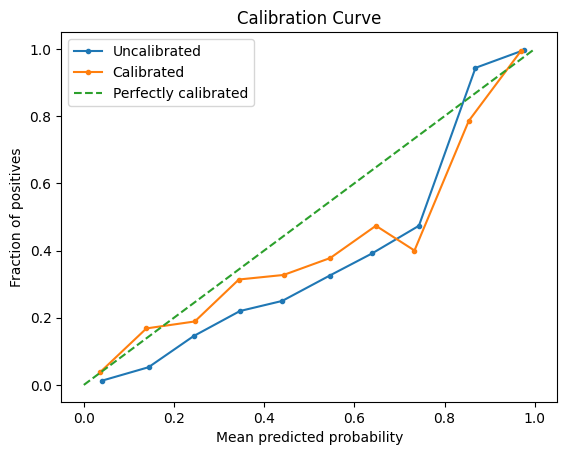

In [ ]:
plt.plot(
    predicted_uncal,
    actual_uncal,
    marker='.',
    label='Uncalibrated'
)

plt.plot(
    predicted_cal,
    actual_cal,
    marker='.',
    label='Calibrated'
)

# Perfect calibration line
plt.plot([0, 1], [0, 1], '--', label='Perfectly calibrated')

plt.xlabel('Mean predicted probability')
plt.ylabel('Fraction of positives')
plt.title('Calibration Curve')
plt.legend()
plt.show()

**SHAP Interpretation - Global & local**
1. shap helps us understand why the model makes a particular decision.
2. it is a way of explaining a 'black_box' model.

**Shap can tell you how each feature contributed**

local explaination 🐜
*  Why did the model make this particular prediction?


Global explaination 🌏

*   Which features are important across the whole dataset?



In [7]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: C:\Users\neeraj\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [ ]:
# get the trained XGBoost classifier model out of the pipeline.
xg_classifier=Xg_model.named_steps['classifier']

# transform X_test  using the same preprocessing used for training.
X_test_transformed=Xg_model.named_steps['preprocessor'].transform(X_test)
# get fetaured  names after one-hot encoding so plots are readable

feature_names=Xg_model.named_steps['preprocessor'].get_feature_names_out()
X_test_df=pd.DataFrame(X_test_transformed,columns=feature_names)
X_test_df.head()

,num__person_age,num__person_income,num__person_emp_length,num__loan_amnt,num__loan_int_rate,num__loan_percent_income,num__cb_person_cred_hist_length,cat__person_home_ownership_MORTGAGE,cat__person_home_ownership_OTHER,cat__person_home_ownership_OWN,...,cat__loan_intent_VENTURE,cat__loan_grade_A,cat__loan_grade_B,cat__loan_grade_C,cat__loan_grade_D,cat__loan_grade_E,cat__loan_grade_F,cat__loan_grade_G,cat__cb_person_default_on_file_N,cat__cb_person_default_on_file_Y
0,24.0,30000.0,1.0,15000.0,15.68,0.50,3.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,23.0,60000.0,6.0,25600.0,13.48,0.43,4.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,29.0,18000.0,2.0,3600.0,15.27,0.20,6.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,32.0,130000.0,7.0,13000.0,12.69,0.10,8.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,23.0,45288.0,7.0,20500.0,9.25,0.45,2.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [ ]:
#create Shap explaier built for tree-based model
import shap
explainer=shap.TreeExplainer(xg_classifier)


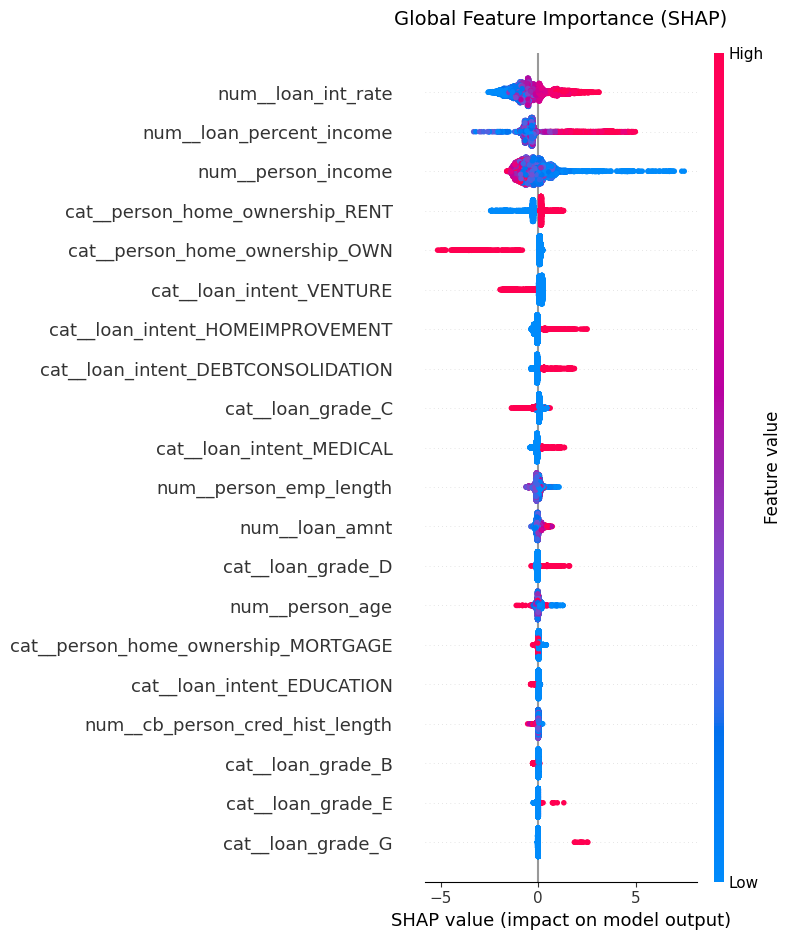

In [ ]:
# Calculate SHAP values for the test dataset
shap_values = explainer(X_test_df)

# 1. Global Explanation: Summary Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_df, show=False)
plt.title("Global Feature Importance (SHAP)", fontsize=14, pad=20)
plt.tight_layout()
plt.show()

enter the row index for local explanation using SHAP: 5


SHAP value for index 5


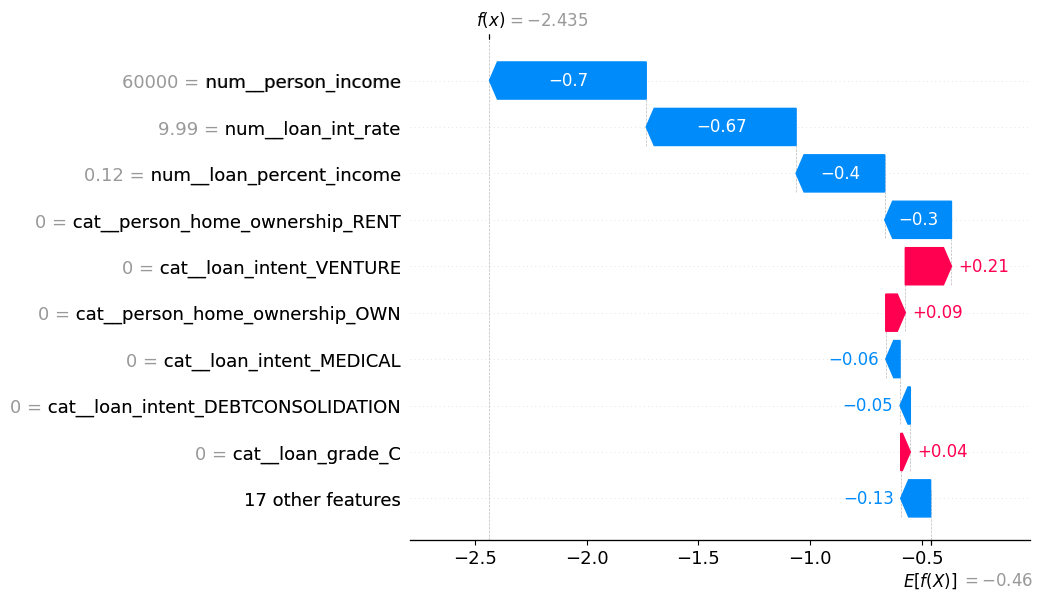

In [ ]:
# 2. Local Explanation: Waterfall plot for the selected prediction row

row_index = int(input("enter the row index for local explanation using SHAP: "))
print("\n")
print(f"SHAP value for index {row_index}")

# In modern SHAP versions, we pass the explanation slice directly to the waterfall function
plt.figure(figsize=(10, 4))
shap.plots.waterfall(shap_values[row_index], max_display=10, show=False)
plt.show()

**Analyzing False Positive  & False Negatives.**

In [ ]:
Y_pred= random_search.predict(X_test)
#
result_df=X_test.copy()
result_df['y_test']=y_test
result_df['y_pred']=Y_pred


In [ ]:
#identify false positive : MODEL predicted 1, but the actual was 0
false_positive=result_df[(result_df['y_test']==0) & (result_df['y_pred']==1)]

# identify false negative : MODEL predicted 0,but the actual was 1
false_negative=result_df[(result_df['y_test']==1) & (result_df['y_pred']==0)]


In [ ]:
print(f"False Positive: {len(false_positive)}")
print(f"False Negative: {len(false_negative)}")

False Positive: 88
False Negative: 318


**False Negative > false Positive**

In [ ]:
# SAVE MODEL

In [ ]:
import joblib
joblib.dump(calibrated_xgb, 'calibrated_xgb_model.pkl')

['calibrated_xgb_model.pkl']

In [ ]:
joblib.dump(best_threshold,"best_threshold")

['best_threshold']

In [ ]:
from sklearn.metrics import precision_recall_curve
import numpy as np

calibrated_proba=calibrated_xgb.predict_proba(X_test)[:,1]
precision,recall,thresholds=precision_recall_curve(y_test,calibrated_proba)
f1_scores=2*precision*recall/(precision+recall+1e-9)
best_threshold=thresholds[np.argmax(f1_scores[:-1])]
print(f"Best Threshold: {best_threshold:.4f}")

Best Threshold: 0.5951
